# Домашнє завдання 11 · LiDAR → RGB: перевірка дальності до об'єктів
**Заняття 11 · RGB + LiDAR / Radar · ≈ 3–4 години · 20 балів**

Збираємо конвеєр зі слайда «ДЗ: LiDAR → RGB для верифікації відстані» на **KITTI object**: хмару Velodyne проєктуємо
на кадр лівої кольорової камери, для кожного об'єкта з розмітки беремо точки в його боксі, рахуємо дальність з LiDAR
і з моно (`f · H / h`) і порівнюємо обидві з дальністю, яку дає 3D-бокс розмітки. Потім ламаємо калібрування і час
і дивимося, наскільки це псує результат. У дужках — назви слайдів.

| Частина | Що робимо | Слайди |
|---|---|---|
| **1 · калібрування і проєкція** | читаємо `calib/*.txt` → `P2 · R0_rect · Tr_velo_to_cam` → `project()` з тестом на синтетиці | «SE(3) і конвенція імен T_to_from», «Осі LiDAR і камери», «Конвенція KITTI» |
| **2 · overlay** | ≥ 5 кадрів, колір = глибина, колорбар | «Point-to-pixel: конвеєр і код», «LiDAR → RGB: колір = глибина» |
| **3 · GT дальності** | 3D-бокс з `label_2` → глибина його видимої поверхні | «Конвенція KITTI» (деталі, що ламають ДЗ) |
| **4 · дальність з LiDAR і з моно** | frustum боксу → перший щільний кластер → медіана; `f · H / h` | «Дальність до цілі: LiDAR vs моно vs стерео» |
| **5 · метрики** | таблиця по об'єктах, MAE / медіана / p90 по бінах 0–20 / 20–40 / 40+ м, відмови окремо | «ДЗ: LiDAR → RGB для верифікації відстані» |
| **6 · абляція** | помилка yaw ±0.5° / ±1° і розсинхрон Δt | «Як довести, що калібрування правильне», «Бюджет похибки синхронізації» |
| **7 · звіт** | чотири короткі висновки | — |

```
velodyne/*.bin ──► P2 · R0_rect · Tr_velo_to_cam ──► (u, v, z) ──► точки в боксі ──► кластер ──► d_lidar ─┐
image_2 + label_2: 2D-бокс, клас ───────────────────────────────────────────────► f · H / h ──► d_mono  ─┼─► |d − d_GT| по бінах
label_2: 3D-бокс ──► видима поверхня ──────────────────────────────────────────────────────► d_GT    ─┘
```

**Як працювати.** Читання файлів, малювання, GT і цикли по кадрах уже написані. Ваше — шість клітинок з `TODO`:
калібрування, проєкція, дальність з LiDAR, дальність з моно, метрики по бінах і збурення калібрування та часу. Після
кожного кроку `check()` показує ✅ або ❌. Відповіді пишете в клітинках «✍️».

In [5]:
import sys
import json
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# спільний код заняття 11: читання KITTI object, розмітка, GT видимої поверхні, статуси відмов — той самий, що в LIVE DEMO 3
REPO = next(
    p for p in [Path.cwd(), *Path.cwd().parents] 
    if (p / 'lessons' / '11-rgb-lidar-radar-fusion').is_dir()
)
sys.path.insert(
    0, 
    str(REPO / 'lessons' / '11-rgb-lidar-radar-fusion')
)
import kitti11 as K11

ROOT = K11.ROOT                   # artifacts/kitti/object/training або змінна KITTI_OBJECT_ROOT
N_FRAMES = 200                    # ≥ 20 кадрів за умовою; перші 200 за номером — у всіх ті самі кадри, у біні 40+ м ≈ 60 об'єктів

missing = [
    d for d in K11.PARTS 
    if not (ROOT / d).is_dir()
]
assert not missing, (f'у {ROOT} немає {missing}. Потрібен KITTI object training: velodyne, image_2, calib, label_2 '
                     '(python tools/fetch_kitti.py --object, див. README завдання) або змінна KITTI_OBJECT_ROOT.')

FRAMES = [
    p.stem 
    for p in sorted((ROOT / 'label_2').glob('*.txt')) 
    if K11.available(p.stem)
][:N_FRAMES]

OUT_DIR = Path('outputs'); 
OUT_DIR.mkdir(exist_ok=True)

pd.set_option('display.precision', 2)
plt.rcParams['figure.dpi'] = 90
print(f'{ROOT}: {len(FRAMES)} кадрів ({FRAMES[0]} … {FRAMES[-1]})')


def check(ok, good, bad):
    print(('✅ ' + good) if ok else ('❌ ' + bad))


def load_points(stem):
    """velodyne/*.bin → N×3, м, у рамці Velodyne (x вперед, y ліворуч, z вгору). Масив лише для читання."""
    return K11.points_image(stem)[0]


def load_image(stem):
    """image_2/*.png → RGB у [0, 1]."""
    return K11.points_image(stem)[1]

/home/adominstrator/cv_projects/UA_COMPUTER-VISION-ADVANCED/artifacts/kitti/object/training: 200 кадрів (000000 … 000199)


# Частина 1 · Калібрування і проєкція

## 1.1 · Ланцюг KITTI (≈ 15 хв)

У `calib/000123.txt` кожен рядок — `ключ: числа`. Нам потрібні три матриці (слайд «Конвенція KITTI»):
- `Tr_velo_to_cam` (3×4) — з рамки Velodyne у рамку cam0. Попри назву «to», за нашою конвенцією це `T_cam0_velo`;
- `R0_rect` (3×3) — поворот ректифікації cam0;
- `P2` (3×4) — з ректифікованої рамки cam0 у пікселі лівої кольорової камери. Зсув cam0 → cam2 (≈ 6 см) уже сидить у `P2[:, 3]`.

Щоб їх перемножити, `R0_rect` і `Tr_velo_to_cam` доповнюємо до 4×4 одиничним рядком і стовпцем.

**TODO 1.1.** Допишіть `load_calib`: `R0` і `Tv` — матриці 4×4, `P = P2 · R0 · Tv` (3×4). Пастка зі слайда: без `R0_rect`
точки зсуваються на кілька пікселів і це легко не помітити на ближніх об'єктах.

In [6]:
def load_calib(path):
    d = {}
    for ln in open(path):
        if ':' in ln:
            k, v = ln.split(':', 1)
            d[k.strip()] = np.array(v.split(), dtype=float)

    # Camera projection matrix: 3x4
    P2 = d['P2'].reshape(3, 4)

    #R0 = Tv = P = ...   # TODO 1.1: R0 і Tv — 4×4, P = P2 · R0 · Tv (3×4)
    # Rectification matrix: 4x4
    R0 = np.eye(4)
    R0[:3, :3] = d['R0_rect'].reshape(3, 3)

    # Velodyne -> Camera transformation: 4x4
    Tv = np.eye(4)
    Tv[:3, :4] = d['Tr_velo_to_cam'].reshape(3, 4)

    # Full LiDAR -> RGB projection: 3x4
    P = P2 @ R0 @ Tv
    
    return dict(P2=P2, R0=R0, Tv=Tv, P=P)


# синтетичний calib з відомими матрицями: R0 — поворот на 1°, щоб пропущений R0_rect було видно
a = np.radians(1.0)
R0_t = np.array([[1, 0, 0], [0, np.cos(a), -np.sin(a)], [0, np.sin(a), np.cos(a)]])
Tr_t = np.array([[0, -1, 0, 0.01], [0, 0, -1, -0.08], [1, 0, 0, -0.27]], float)
P2_t = np.array([[720, 0, 610, 44], [0, 720, 175, 0.2], [0, 0, 1, 0.003]], float)
test_path = OUT_DIR / '_calib_test.txt'
test_path.write_text('\n'.join(f'{k}: ' + ' '.join(map(str, m.ravel()))
                               for k, m in (('P2', P2_t), ('R0_rect', R0_t), ('Tr_velo_to_cam', Tr_t))) + '\n')
c_t = load_calib(test_path)
want = P2_t @ np.block([[R0_t, np.zeros((3, 1))], [np.zeros((1, 3)), 1]]) @ np.vstack([Tr_t, [0, 0, 0, 1]])
calib0 = load_calib(ROOT / 'calib' / f'{FRAMES[0]}.txt')
y = calib0['P'] @ np.array([10.0, 0, 0, 1])                  # точка 10 м прямо попереду Velodyne
check(np.shape(c_t['P']) == (3, 4) and np.allclose(c_t['P'], want) and 9 < y[2] < 11 and abs(y[0] / y[2] - calib0['P2'][0, 2]) < 60,
      f"ланцюг зібрано; кадр {FRAMES[0]}: точка 10 м попереду → u = {y[0] / y[2]:.0f} (cx = {calib0['P2'][0, 2]:.0f}), z = {y[2]:.2f} м",
      'P має бути 3×4 і дорівнювати P2 · R0 · Tv; точка 10 м попереду — z ≈ 10 м і u біля cx')

✅ ланцюг зібрано; кадр 000000: точка 10 м попереду → u = 606 (cx = 604), z = 9.67 м


## 1.2 · Проєкція точок (≈ 20 хв)

Конвеєр зі слайда «Point-to-pixel»: однорідні координати → `P` → лишаємо точки **перед камерою** (`z > zmin`) → ділимо
на `z` → лишаємо ті, що потрапили в кадр. Без фільтра `z > 0` точки позаду камери після ділення на від'ємне `z`
з'являються в кадрі дзеркально.

**TODO 1.2.** `project(pts, P, W, H, zmin)` повертає `uv` (N×2, float), `z` (N) і булеву маску `m` (N): `z > zmin`
і `0 ≤ u < W`, `0 ≤ v < H`. Довжини всіх трьох — N, тобто як у вхідних точках; маску застосовує той, хто викликає.
Тест нижче перевіряє функцію на синтетиці з відомою відповіддю: заданий вручну pinhole, точки спереду, позаду й поза кадром.

In [7]:
# перетворення 3D-координат точок LiDAR у 2D-координати пікселів RGB-зображення.
def project(pts, P, W, H, zmin=0.5):
    """pts: N×3 у рамці Velodyne → uv (N×2), z (N), m (N, bool): перед камерою і в кадрі."""
    #uv = z = m = ...   # TODO 1.2: однорідні координати → P → z → ділення на z → маска
    # 1. Перетворюємо точки у однорідні координати
    pts_h = np.c_[pts, np.ones(len(pts))]

    # 2. Проєктуємо точки через матрицю P
    proj = pts_h @ P.T

    # 3. Отримуємо глибину
    z = proj[:, 2]

    # 4. Обчислюємо координати пікселів
    uv = np.full((len(pts), 2), np.nan)

    valid_z = z > zmin

    uv[valid_z] = (
        proj[valid_z, :2] / z[valid_z, None]
    )

    # 5. Відбираємо точки перед камерою і всередині кадру
    m = (
        valid_z &
        (uv[:, 0] >= 0) &
        (uv[:, 0] < W) &
        (uv[:, 1] >= 0) &
        (uv[:, 1] < H)
    )
    
    return uv, z, m


# синтетика: камера з f = 700 px дивиться вперед, оптичний центр (600, 180), кадр 1200 × 360
K_s = np.array([[700, 0, 600], [0, 700, 180], [0, 0, 1.0]])
R_axes = np.array([[0, -1, 0], [0, 0, -1], [1, 0, 0.0]])        # FLU (Velodyne) → RDF (камера)
t_s = np.array([0.0, -0.08, -0.27])
P_s = K_s @ np.c_[R_axes, t_s]
rng = np.random.default_rng(0)
pts_s = np.c_[rng.uniform(-30, 60, 2000), rng.uniform(-25, 25, 2000), rng.uniform(-2, 3, 2000)]
Xc = pts_s @ R_axes.T + t_s
with np.errstate(divide='ignore', invalid='ignore'):
    u_want, v_want = 700 * Xc[:, 0] / Xc[:, 2] + 600, 700 * Xc[:, 1] / Xc[:, 2] + 180
m_want = (Xc[:, 2] > 0.5) & (u_want >= 0) & (u_want < 1200) & (v_want >= 0) & (v_want < 360)
uv_s, z_s, m_s = project(pts_s, P_s, 1200, 360)
uv10, z10, _ = project(np.array([[10.0, 0, 0]]), P_s, 1200, 360)
check(np.shape(uv_s) == (2000, 2) and np.array_equal(m_s, m_want) and np.allclose(uv_s[m_s], np.c_[u_want, v_want][m_want])
      and np.allclose(z_s[m_s], Xc[m_want, 2]) and abs(uv10[0, 0] - 600) < 1e-6 and abs(z10[0] - 9.73) < 1e-6,
      f'проєкція збігається з pinhole; у кадр потрапило {m_s.sum()} з 2000 точок, усі позаду камери відкинуто',
      'перевірте множення на P, ділення на z і маску (z > zmin і межі кадру)')

✅ проєкція збігається з pinhole; у кадр потрапило 984 з 2000 точок, усі позаду камери відкинуто


# Частина 2 · Overlay: колір = глибина (≈ 10 хв, код готовий)

Колір — логарифм глибини, як на слайді «LiDAR → RGB»: інакше всі точки далі 20 м зливаються в один колір. Збережіть
щонайменше 5 overlay. Подивіться на тонкі вертикалі (стовпи, краї машин) на різних дальностях: якщо точки «з'їжджають»
з краю однаково близько й далеко — це поворот, якщо лише близько — зсув (слайд «Як довести, що калібрування правильне»).
Висновок напишете в 7.1, після кропів у частині 5.

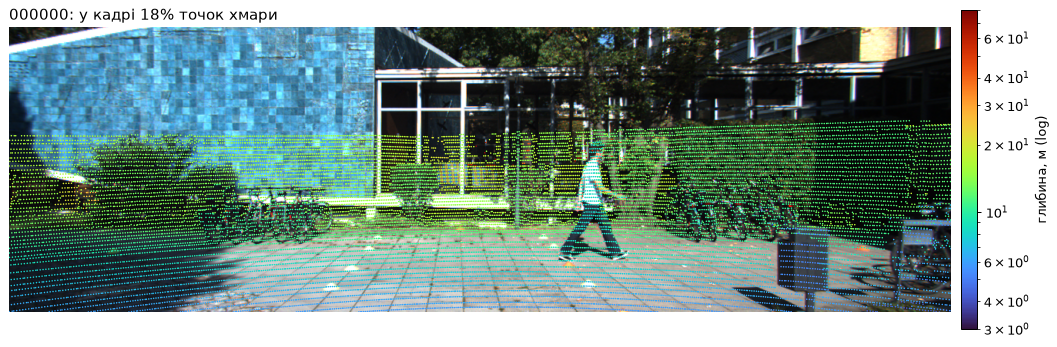

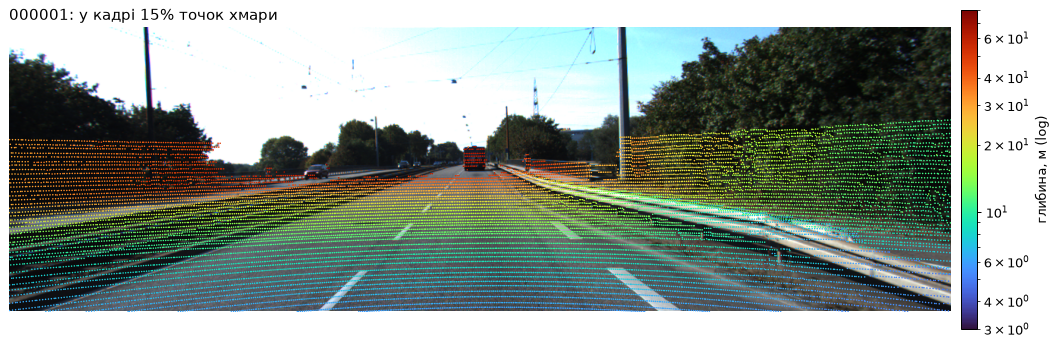

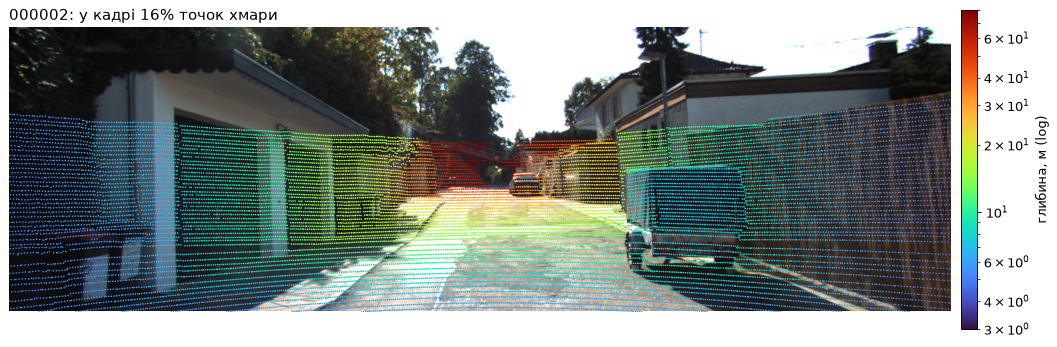

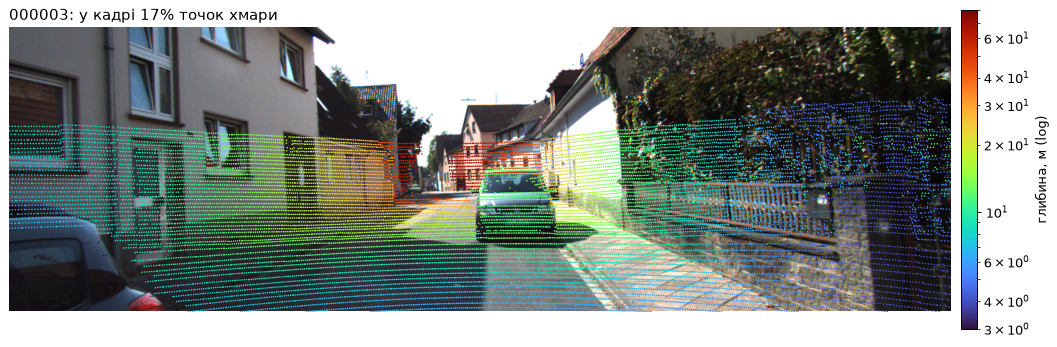

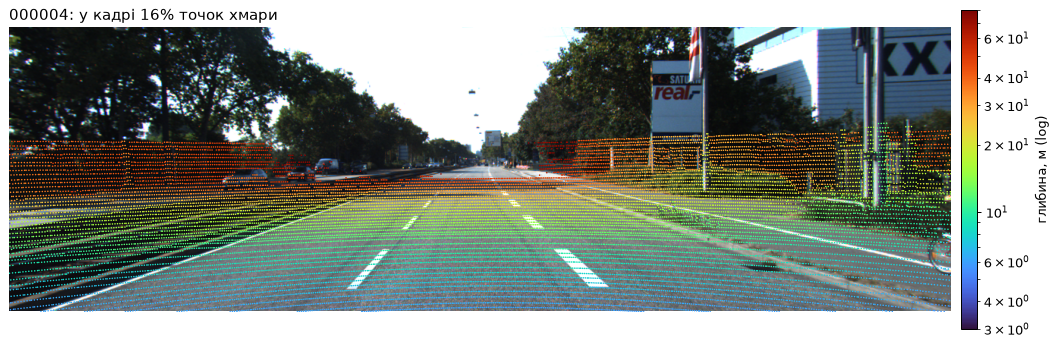

✅ збережено 5 overlay в outputs/


In [8]:
DEPTH_NORM = plt.matplotlib.colors.LogNorm(vmin=3, vmax=80)

def overlay(stem, ax=None, P=None, s=1.5):
    img, pts = load_image(stem), load_points(stem)
    c = load_calib(ROOT / 'calib' / f'{stem}.txt')
    uv, z, m = project(pts, c['P'] if P is None else P, img.shape[1], img.shape[0])
    ax = ax or plt.gca()
    ax.imshow(img)
    sc = ax.scatter(uv[m, 0], uv[m, 1], c=z[m], s=s, cmap='turbo', norm=DEPTH_NORM, lw=0)
    ax.set_xlim(0, img.shape[1]); ax.set_ylim(img.shape[0], 0); ax.set_axis_off()
    return sc, m.mean()


OVERLAYS = FRAMES[:5]
for stem in OVERLAYS:
    fig, ax = plt.subplots(figsize=(14, 4.6))
    sc, share = overlay(stem, ax)
    ax.set_title(f'{stem}: у кадрі {share:.0%} точок хмари', loc='left')
    fig.colorbar(sc, ax=ax, fraction=0.025, pad=0.01, label='глибина, м (log)')
    fig.savefig(OUT_DIR / f'overlay_{stem}.png', bbox_inches='tight')
    plt.show()
check(all((OUT_DIR / f'overlay_{s}.png').exists() for s in OVERLAYS), f'збережено {len(OVERLAYS)} overlay в {OUT_DIR}/',
      'overlay не збережено')

# Частина 3 · GT дальності (≈ 10 хв, код готовий)

`label_2` дає для кожного об'єкта клас, прапорці `truncated` (0…1) і `occluded` (0 — видно повністю … 3 — невідомо),
2D-бокс у пікселях `image_2`, розміри `h, w, l` (м), `location` — **центр нижньої грані** 3D-боксу в ректифікованій
рамці cam0 — і поворот `ry` навколо вертикалі.

**Що вважати еталонною дальністю.** LiDAR бачить **поверхню**, повернуту до сенсора, а `location.z` — це центр боксу.
Для машини, яка стоїть до нас задом, різниця — половина довжини, ≈ 2 м, тобто в чотири рази більше за поріг 0.5 м з умови.
Тому за `d_GT` беремо медіанну глибину **видимої поверхні** 3D-боксу: через сітку пікселів його 2D-боксу пускаємо промені
з камери і для кожного беремо точку, де промінь входить у бокс. Сітка рівномірна в пікселях, як і точки LiDAR (вони рівномірні
за кутом), тож довгий бік машини, що в кадрі займає вузьку смужку, не перетягує медіану. Це та сама величина, яку міряє
кластер LiDAR, але порахована лише з розмітки. Для порівняння таблиця нижче показує й «наївні» варіанти: центр боксу і найближчу вершину.

In [9]:
# код — у lessons/11-rgb-lidar-radar-fusion/kitti11.py, той самий, що в LIVE DEMO 3
from kitti11 import CLASS_H, labels as load_labels, box_corners, visible_depth

objs0 = load_labels(FRAMES[0])
print(pd.DataFrame([dict(cls=o['cls'], occl=o['occl'], trunc=o['trunc'],
                         d_GT=visible_depth(o, calib0['P2']), центр=o['loc'][2], вершина=box_corners(o)[:, 2].min())
                    for o in objs0]).to_string())

          cls  occl  trunc  d_GT  центр  вершина
0  Pedestrian     0    0.0  8.18   8.41     8.16


# Частина 4 · Дальність з LiDAR і з моно

## 4.1 · LiDAR: frustum → перший щільний кластер → медіана (≈ 40 мін)

У 2D-бокс потрапляють не лише точки об'єкта, а й земля під ним, фон за ним і все, що стоїть перед ним. Тому медіана
**всіх** точок у боксі — погана оцінка. Робимо так, як у LIVE DEMO 3:
1. беремо точки, чия проєкція в боксі (frustum). Бокс можна трохи звузити (`shrink` — частка з кожного боку), щоб
   на краях менше чіплялося фону;
2. якщо точок менше `min_pts` — дальності немає: повертаємо `(None, n)`. Це відмова, вона піде в таблицю окремим рядком;
3. гістограма глибин з кроком `bin_m`; перший від сенсора бін, у якому точок не менше `max(min_pts, 0.15 · max)`, —
   початок кластера. Поріг потрібен, щоб окремі точки пилу чи сусіднього об'єкта не стали «першим кластером»;
4. кластер — точки в межах `cluster_m` від початку біна; дальність — їхня медіана.

**TODO 4.1.** Функція повертає `(d, n)`: дальність у метрах або `None` і кількість точок у frustum.

In [10]:
def lidar_range(uv, z, box, shrink=0.1, bin_m=0.5, min_pts=5, cluster_m=2.0):
    x0, y0, x1, y1 = box
    
    dx = (x1 - x0) * shrink
    dy = (y1 - y0) * shrink
    
    # 1. Вибираємо точки всередині звуженого Bounding Box
    mask = (
        (uv[:, 0] >= x0 + dx) &
        (uv[:, 0] < x1 - dx) &
        (uv[:, 1] >= y0 + dy) &
        (uv[:, 1] < y1 - dy) &
        np.isfinite(z) &
        (z > 0)
    )

    depths = z[mask]
    n = len(depths)

    # 2. Недостатньо точок — відмова
    if n < min_pts:
        return None, n

    # 3. Будуємо гістограму глибин
    edges = np.arange(
        0,
        depths.max() + 2 * bin_m,
        bin_m
    )

    hist, edges = np.histogram(depths, bins=edges)

    # Мінімальна щільність для кластера
    threshold = max(min_pts, 0.15 * hist.max())

    # Шукаємо перший щільний бін
    dense_bins = np.where(hist >= threshold)[0]

    if len(dense_bins) == 0:
        return None, n

    first_bin = dense_bins[0]

    # 4. Початок першого щільного кластера
    cluster_start = edges[first_bin]

    # Вибираємо точки кластера
    cluster = depths[
        (depths >= cluster_start) &
        (depths < cluster_start + cluster_m)
    ]

    if len(cluster) < min_pts:
        return None, n

    # 5. Медіанна глибина кластера
    d = float(np.median(cluster))

    return d, n


# синтетичний frustum: машина на 12 м (60 точок), земля 8–30 м, стіна на 35 м (300 точок), дві «пилинки» на 4 м
rng = np.random.default_rng(1)
z_p = np.r_[rng.normal(12.2, 0.15, 60), rng.uniform(8, 30, 40), rng.normal(35, 0.05, 300), [4.0, 4.1]]
uv_p = rng.uniform([110, 60], [190, 140], (len(z_p), 2))
d_p, n_p = lidar_range(uv_p, z_p, (100, 50, 200, 150), shrink=0.0)
d_few, n_few = lidar_range(uv_p[:4], z_p[:4], (100, 50, 200, 150), shrink=0.0)
check(d_p is not None and abs(d_p - 12.2) < 0.3 and n_p == len(z_p) and d_few is None and n_few == 4,
      f'машина на 12.2 м → {d_p:.2f} м з {n_p} точок; 4 точки → відмова',
      f'очікується ≈ 12.2 м (не стіна на 35 м і не пил на 4 м) і None для 4 точок; маємо {d_p}, {d_few}')

✅ машина на 12.2 м → 12.21 м з 402 точок; 4 точки → відмова


## 4.2 · Моно з відомим розміром (≈ 5 хв)

`Z = f · H / h`: `f` — фокусна відстань у пікселях (`P2[0, 0]`), `H` — **апріорна** висота класу з `CLASS_H` (не з
розмітки: на борту справжньої висоти немає), `h` — висота 2D-боксу в пікселях. Похибка — і від розміру конкретної машини,
і від ±2 px на краях боксу (слайд «Дальність до цілі»).

**TODO 4.2.** Одна формула.

In [11]:
def mono_range(box, H_class, f):
    # TODO 4.2: f · H / h, h — висота боксу в пікселях
    h = box[3] - box[1]
    return f * H_class / h if h > 0 else None


check(abs(mono_range(np.array([0, 100, 50, 135]), 1.75, 1000) - 50) < 1e-9,
      'людина 35 px при f = 1000 px → 50 м', 'людина висотою 35 px при f = 1000 px має бути на 50 м')

✅ людина 35 px при f = 1000 px → 50 м


# Частина 5 · Таблиця і метрики

## Таблиця по об'єктах (≈ 5 хв, код готовий)

Кожен об'єкт отримує `status`. Метрики рахуємо лише по `ok`, а відмови показуємо окремо (критерій з умови):
- `оклюзія` — `occluded ≥ 2`: бокс закриває інший об'єкт, і перший кластер легко виявиться ним;
- `обрізаний` — `truncated > 0.3`: бокс урізаний краєм кадру, моно з такою висотою боксу бреше;
- `малий бокс` — висота < 25 px (поріг KITTI moderate);
- `< 5 точок` — LiDAR не дав дальності.

In [12]:
def frame_rows(stem, P=None):
    c = load_calib(ROOT / 'calib' / f'{stem}.txt')
    img_h, img_w = load_image(stem).shape[:2]
    uv, z, m = project(load_points(stem), c['P'] if P is None else P, img_w, img_h)
    rows = []
    for o in load_labels(stem):
        d_l, n = lidar_range(uv[m], z[m], o['box'])
        h_px = o['box'][3] - o['box'][1]
        status = K11.status(o)
        status = '< 5 точок' if status == 'ok' and d_l is None else status
        rows.append(dict(frame=stem, cls=o['cls'], status=status, occl=o['occl'], trunc=o['trunc'], h_px=h_px, n_pts=n,
                         d_gt=visible_depth(o, c['P2']), d_center=o['loc'][2],
                         d_lidar=np.nan if d_l is None else d_l, d_mono=mono_range(o['box'], CLASS_H[o['cls']], c['P2'][0, 0])))
    return rows


df = pd.DataFrame([r for s in FRAMES for r in frame_rows(s)])
df['err_lidar'] = df.d_lidar - df.d_gt
df['err_mono'] = df.d_mono - df.d_gt
df['err_center'] = df.d_center - df.d_gt
ok = df[(df.status == 'ok') & df.d_gt.notna()]
df.to_csv(OUT_DIR / 'objects.csv', index=False)
print(f"об'єктів: {len(df)} у {df.frame.nunique()} кадрах, з них ok: {len(ok)}")
print(df.status.value_counts().rename('відмови і ok').to_string())
display(df.head(12))
check(df.frame.nunique() >= 20 and len(ok) >= 50, f"{df.frame.nunique()} кадрів, {len(ok)} об'єктів у метриках",
      "за умовою потрібно ≥ 20 кадрів і ≥ 50 об'єктів — збільште N_FRAMES")

об'єктів: 973 у 200 кадрах, з них ok: 580
status
ok            580
оклюзія       233
малий бокс     95
обрізаний      65


,frame,cls,status,occl,trunc,h_px,n_pts,d_gt,d_center,d_lidar,d_mono,err_lidar,err_mono,err_center
0,000000,Pedestrian,ok,0,0.0,164.92,961,8.18,8.41,8.34,7.50,0.17,-0.67,0.23
1,000001,Truck,ok,0,0.0,32.85,61,63.27,69.44,63.37,70.29,0.10,7.01,6.17
2,000001,Car,малий бокс,0,0.0,21.58,10,56.65,58.49,56.79,51.16,0.14,-5.49,1.84
3,000001,Cyclist,оклюзія,3,0.0,29.98,18,44.83,45.84,45.79,41.88,0.95,-2.96,1.01
4,000002,Car,ok,0,0.0,33.26,81,32.20,34.38,33.27,33.19,1.07,0.99,2.18
5,000003,Car,ok,0,0.0,102.99,624,11.15,13.22,11.47,10.72,0.31,-0.43,2.07
6,000004,Car,ok,0,0.0,30.49,71,36.26,38.26,36.61,36.21,0.35,-0.05,2.00
7,000004,Car,малий бокс,0,0.0,20.66,24,49.47,51.17,49.70,53.43,0.23,3.96,1.70
8,000005,Pedestrian,ok,0,0.0,59.90,104,22.70,23.02,22.97,21.08,0.28,-1.62,0.32
9,000006,Car,оклюзія,2,0.0,23.09,16,46.41,48.22,46.73,47.60,0.32,1.18,1.81


✅ 200 кадрів, 580 об'єктів у метриках


## 5.1 · Метрики по бінах дальності (≈ 20 хв)

Біни — за еталонною дальністю `d_GT`: `0–20 м`, `20–40 м`, `40+ м`. У кожному біні — кількість об'єктів `N` і для
**модуля** похибки `MAE`, медіана і `p90`. `N` обов'язково: медіана з трьох об'єктів і з тридцяти важить по-різному.

**TODO 5.1.** `metrics_by_bin(err, d_gt)` повертає `DataFrame` з індексом `BINS` і стовпцями `N, MAE, median, p90`.
Порожній бін — `N = 0` і `NaN` у решті.

In [13]:
BINS = {'0–20 м': (0, 20), '20–40 м': (20, 40), '40+ м': (40, np.inf)}


def metrics_by_bin(err, d_gt):
    err = np.asarray(err, float)
    d_gt = np.asarray(d_gt, float)
    # TODO 5.1: для кожного біна — N і MAE / медіана / p90 модуля похибки
    masks = [
        (d_gt >= 0) & (d_gt < 20),
        (d_gt >= 20) & (d_gt < 40),
        (d_gt >= 40)
    ]

    rows = []

    for mask in masks:
        # Враховуємо тільки значення без NaN
        valid = mask & np.isfinite(err) & np.isfinite(d_gt)

        abs_err = np.abs(err[valid])
        n = len(abs_err)

        rows.append({
            'N': n,
            'MAE': np.mean(abs_err) if n else np.nan,
            'median': np.median(abs_err) if n else np.nan,
            'p90': np.percentile(abs_err, 90) if n else np.nan
        })

    return pd.DataFrame(rows, index=BINS)


probe = metrics_by_bin([0.1, -0.3, 0.2, 2.0, -1.0], [5, 10, 15, 30, 35])
check(isinstance(probe, pd.DataFrame) and list(probe.index) == list(BINS) and probe.N.tolist() == [3, 2, 0]
      and np.isclose(probe.loc['0–20 м', 'MAE'], 0.2) and np.isclose(probe.loc['20–40 м', 'median'], 1.5)
      and np.isnan(probe.loc['40+ м', 'MAE']),
      'метрики по бінах рахуються правильно', 'очікуються N = [3, 2, 0], MAE 0–20 м = 0.2, медіана 20–40 м = 1.5, порожній бін — NaN')

✅ метрики по бінах рахуються правильно


In [14]:
same = ok[ok.d_lidar.notna() & ok.d_mono.notna()]          # усі методи — на тих самих об'єктах
M = {'LiDAR': metrics_by_bin(same.err_lidar, same.d_gt), 'моно': metrics_by_bin(same.err_mono, same.d_gt),
     'центр боксу замість поверхні': metrics_by_bin(same.err_center, same.d_gt)}
display(pd.concat(M, axis=1))
med = M['LiDAR'].loc[['0–20 м', '20–40 м'], 'median']
check(bool((med.dropna() <= 0.5).all()), f'медіана |d_lidar − d_GT| до 40 м: {med.round(2).tolist()} м — критерій ≤ 0.5 м виконано',
      f'медіана до 40 м = {med.round(2).tolist()} м > 0.5 м: знайдіть причину й поясніть її у звіті (7.2)')

LiDAR                     моно                     \
            N   MAE median    p90    N   MAE median   p90   
0–20 м    244  0.84   0.26   2.93  244  0.78   0.60  1.63   
20–40 м   277  2.59   0.25  10.28  277  1.99   1.61  4.41   
40+ м      59  3.17   0.15  11.22   59  4.56   3.56  8.41   

        центр боксу замість поверхні                     
                                   N   MAE median   p90  
0–20 м                           244  1.38   1.66  2.14  
20–40 м                          277  1.55   1.78  2.18  
40+ м                             59  2.28   1.85  5.97

✅ медіана |d_lidar − d_GT| до 40 м: [0.26, 0.25] м — критерій ≤ 0.5 м виконано


In [15]:
same.groupby('cls').size()

cls
Car           420
Cyclist        31
Pedestrian     84
Truck          12
Van            33
dtype: int64

In [16]:
result = same.groupby('cls').agg(
    N=('err_mono', 'count'),
    MAE=('err_mono', lambda x: x.abs().mean()),
    median=('err_mono', lambda x: x.abs().median()),
    p90=('err_mono', lambda x: x.abs().quantile(0.9))
).sort_values('MAE', ascending=False)

display(result.round(2))

,N,MAE,median,p90
cls,,,,
Truck,12,5.49,6.70,7.68
Van,33,4.98,4.09,9.54
Car,420,1.59,1.07,3.65
Pedestrian,84,1.07,0.78,2.46
Cyclist,31,0.69,0.48,1.63


## Кропи на трьох дальностях (≈ 5 хв, код готовий)

Найближчий, середній і найдальший об'єкт з `ok`: бокс розмітки, точки LiDAR кольором глибини. Це матеріал для 7.1
(точки на краях об'єктів) і для частини 6.

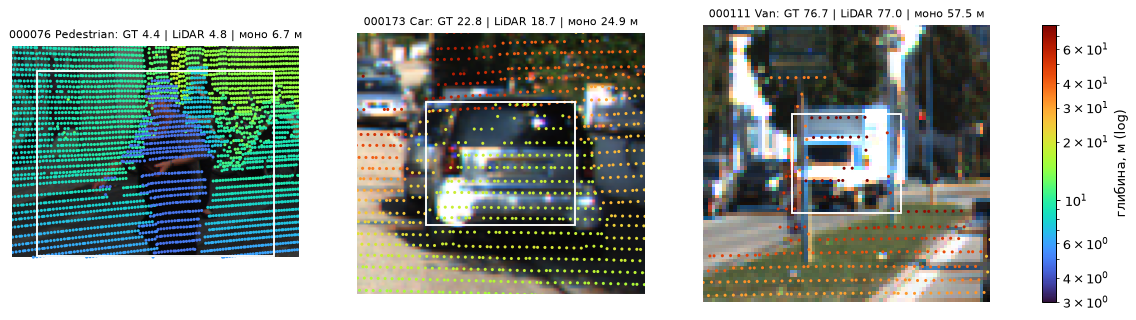

In [17]:
def crop(row, ax, P=None, pad=25):
    stem = row.frame
    sc, _ = overlay(stem, ax, P=P, s=6)
    o = next(o for o in load_labels(stem) if np.isclose(o['box'][3] - o['box'][1], row.h_px) and o['cls'] == row.cls)
    x0, y0, x1, y1 = o['box']
    ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec='w', lw=1.5))
    ax.set_xlim(x0 - pad, x1 + pad); ax.set_ylim(y1 + pad, y0 - pad)
    ax.set_title(f"{stem} {row.cls}: GT {row.d_gt:.1f} | LiDAR {row.d_lidar:.1f} | моно {row.d_mono:.1f} м", fontsize=9)
    return sc


picks = same.sort_values('d_gt').iloc[[0, len(same) // 2, -1]]
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, (_, r) in zip(axs, picks.iterrows()):
    sc = crop(r, ax)
fig.colorbar(sc, ax=axs, fraction=0.015, label='глибина, м (log)')
fig.savefig(OUT_DIR / 'crops.png', bbox_inches='tight')
plt.show()

Кадр	Об'єкт	     GT	      LiDAR	    Абсолютна похибка
000076	Pedestrian	 4.4 м	  4.8 м	    0.4 м
000173	Car	         22.8 м	  18.7 м	4.1 м
000111	Van	         76.7 м	  77.0 м	0.3 м

Кадр 000076 — близький об'єкт, 4.4 м
LiDAR-точки щільно покривають пішохода, добре видно його силует на фоні інших точок.
- На межах тіла спостерігається перехід між ближніми синіми точками та дальніми зеленими.
- Межі цього переходу загалом відповідають контуру пішохода.
- Похибка дальності становить приблизно 0.4 м.
суміщення виглядає задовільним. Вираженого систематичного зсуву не видно.

Кадр 000173 — середня дальність, 22.8 м
На зображенні автомобіль частково покривається точками різної глибини.
- У межах білого Bounding Box є точки автомобіля, а також точки навколишніх поверхонь.
- Частина точок на краях боксу належить фону або сусіднім об'єктам.
- LiDAR визначив 18.7 м замість еталонних 22.8 м — похибка 4.1 м.
Це найбільш проблемний із трьох прикладів. Імовірно, алгоритм lidar_range() вибрав ближчий кластер, який не відповідає основній видимій поверхні автомобіля. Це не обов'язково помилка калібрування: навіть за правильної проєкції всередині 2D-боксу можуть бути точки сторонніх об'єктів.

Кадр 000111 — далекий об'єкт, 76.7 м
На великій дальності LiDAR-точок значно менше.
- Точки в області фургона розріджені.
- Частина точок потрапляє на контури кузова, але точність суміщення важко оцінити через малу щільність.
- LiDAR визначив 77.0 м проти GT 76.7 м — похибка лише 0.3 м.
Попри велику дальність, оцінка глибини вийшла точною. Однак невелика похибка дальності сама по собі не доводить ідеальну калібровку.

# Частина 6 · Абляція: калібрування і час

## 6.1 · Збурення `P` (≈ 30 хв)

Дві помилки, які дають «майже правильний» overlay:
- **yaw калібрування** — поворот на малий кут навколо вертикальної осі камери (вісь `y` рамки cam0, вниз). Множимо його
  між `R0` і `Tv`: `P' = P2 · R0 · R_y(yaw) · Tv`. На слайді «Як довести»: Δu ≈ f · δθ на будь-якій дальності;
- **розсинхрон Δt** — кадр знято на Δt пізніше за скан, а машина за цей час проїхала `v · Δt` вперед і повернула на
  `ω · Δt` ліворуч. Точку треба перевести в рамку Velodyne на момент кадру: `X' = R_z(ω·Δt)ᵀ · (X − [v·Δt, 0, 0])`,
  тобто `P' = P · M`, де `M` — це перетворення 4×4. Чистий поворот дає Δu ≈ f · ω · Δt (слайд «Бюджет похибки синхронізації»).

**TODO 6.1.** `perturb_P(c, yaw_deg, dt_s, v, w_deg)` повертає 3×4. При нульових збуреннях — рівно `c['P']`.

In [18]:
def perturb_P(c, yaw_deg=0.0, dt_s=0.0, v=10.0, w_deg=30.0):
    """c — результат load_calib; v — швидкість вперед, м/с; w_deg — рискання ліворуч, °/с."""
    # TODO 6.1: R_y(yaw) між R0 і Tv; M = [R_z(ω·Δt)ᵀ | −R_z(ω·Δt)ᵀ · (v·Δt, 0, 0)]
    # 1. Помилка yaw калібрування (навколо осі Y камери)
    yaw = np.radians(yaw_deg)

    Ry = np.eye(4)
    Ry[:3, :3] = [
        [ np.cos(yaw), 0, np.sin(yaw)],
        [ 0,           1, 0          ],
        [-np.sin(yaw), 0, np.cos(yaw)]
    ]

    # 2. Рух автомобіля між LiDAR і RGB
    angle = np.radians(w_deg) * dt_s

    Rz = np.array([
        [np.cos(angle), -np.sin(angle), 0],
        [np.sin(angle),  np.cos(angle), 0],
        [0,              0,             1]
    ])

    R = Rz.T

    translation = np.array([v * dt_s, 0, 0])

    M = np.eye(4)
    M[:3, :3] = R
    M[:3, 3] = -R @ translation

    # 3. Нова матриця проєкції
    P_new = c['P2'] @ c['R0'] @ Ry @ c['Tv'] @ M

    return P_new


def u_of(P, X):
    y = P @ np.r_[X, 1.0]
    return y[0] / y[2], y[2]


f0 = calib0['P2'][0, 0]
X30 = np.array([30.0, 0, 0])
u0, z0 = u_of(calib0['P'], X30)
du_yaw = u_of(perturb_P(calib0, yaw_deg=1.0), X30)[0] - u0
du_w = u_of(perturb_P(calib0, dt_s=0.05, v=0.0, w_deg=30.0), X30)[0] - u0
dz_v = u_of(perturb_P(calib0, dt_s=0.1, v=10.0, w_deg=0.0), X30)[1] - z0
check(np.allclose(perturb_P(calib0), calib0['P']) and abs(abs(du_yaw) - f0 * np.radians(1.0)) < 0.1 * f0 * np.radians(1.0)
      and abs(abs(du_w) - f0 * np.radians(1.5)) < 0.1 * f0 * np.radians(1.5) and abs(dz_v + 1.0) < 0.05,
      f'yaw 1° → Δu = {du_yaw:+.1f} px (f·δθ = {f0 * np.radians(1):.1f}); 30°/с × 50 мс → {du_w:+.1f} px; '
      f'10 м/с × 100 мс → глибина {dz_v:+.2f} м',
      'без збурень має бути P; yaw 1° — |Δu| ≈ f·δθ; 30°/с × 50 мс — |Δu| ≈ f·1.5°; 10 м/с × 100 мс — точка на 1 м ближча')

✅ yaw 1° → Δu = +12.3 px (f·δθ = 12.3); 30°/с × 50 мс → +18.7 px; 10 м/с × 100 мс → глибина -1.00 м


## 6.2 · Як збурення псують дальність (≈ 5 хв, код готовий)

Ті самі `ok`-об'єкти, ті самі бокси; змінюється лише `P`. `> 1 м` — частка об'єктів, де дальність LiDAR відхилилась від
GT більше ніж на метр: кластер «з'їхав» на фон або землю. Δt — при 10 м/с і 30°/с, звичайний поворот машини на перехресті.

In [19]:
CASES = [('без збурень', {}), ('yaw −1°', dict(yaw_deg=-1.0)), ('yaw −0.5°', dict(yaw_deg=-0.5)),
         ('yaw +0.5°', dict(yaw_deg=0.5)), ('yaw +1°', dict(yaw_deg=1.0)),
         ('Δt 10 мс', dict(dt_s=0.01)), ('Δt 50 мс', dict(dt_s=0.05)), ('Δt 100 мс', dict(dt_s=0.1))]
keys = set(zip(same.frame, same.cls, same.h_px))
abl = {}
for name, kw in CASES:
    rows = []
    for stem in FRAMES:
        c = load_calib(ROOT / 'calib' / f'{stem}.txt')
        rows += [r for r in frame_rows(stem, P=perturb_P(c, **kw)) if (r['frame'], r['cls'], r['h_px']) in keys]
    a = pd.DataFrame(rows)
    err = (a.d_lidar - a.d_gt).fillna(np.inf)               # дальність зникла — теж провал
    mb = metrics_by_bin(err.clip(upper=99), a.d_gt)
    abl[name] = {**{f'медіана {b}': mb.loc[b, 'median'] for b in BINS},
                 '> 1 м': float((err.abs() > 1).mean())}
ABL = pd.DataFrame(abl).T
display(ABL.style.format({**{f'медіана {b}': '{:.2f}' for b in BINS}, '> 1 м': '{:.0%}'}))

,медіана 0–20 м,медіана 20–40 м,медіана 40+ м,> 1 м
без збурень,0.26,0.25,0.15,23%
yaw −1°,0.27,0.35,0.33,28%
yaw −0.5°,0.26,0.25,0.19,24%
yaw +0.5°,0.26,0.26,0.21,24%
yaw +1°,0.27,0.31,0.47,28%
Δt 10 мс,0.18,0.18,0.14,22%
Δt 50 мс,0.35,0.49,4.60,33%
Δt 100 мс,0.83,4.06,26.04,56%


✍️ **Висновок 6.2** (2–3 речення, входить у бали звіту 7.3): у якому біні yaw ±1° шкодить найбільше і чому дальність
LiDAR узагалі псується, хоча самі точки не змінились? Порівняйте Δt 50 мс при 30°/с з yaw: який розсинхрон «коштує»
стільки ж, скільки 1° калібрування, і що це означає для бюджету з слайда «Бюджет похибки синхронізації»?

✍️ При yaw з -1° до +1° медіанна похибка на 40+ м зростає з 0.15 до 0.47 м, тобто приблизно в 3.1 раза.
3D-точки LiDAR не зміннюються, але змінюється матриця проєкції P, через що точки попадають в інші координати rgb-зображення. На веливій відстані обєкти дуже малі (мало піксілів). Незначний поворот калібрування змістить точки на межі 2d-боксу, як наслідок lidar_range оброюляє інший набір точок.

30°/с * 0.050 с = 1.5° - розсинхронізація 50 мс створює кутову складову зміщення (приблизно 1.5° yaw)
а часовий зсув в 1°: 1° / 30°/с = 0.033333c
а розсинхронізація в 50 мс створює поступальне зміщення 10*0.050 = 0.5м
тобто її вплив це не тільки поворот.
тобто при:
- допустимій кутовій похибці в 1°
- швидкості повороту 30°/с
розсинхронізація повинна бути меншою за приблизно 33 мс

# Частина 7 · Звіт

Коротко, по 2–4 речення, з числами з таблиць вище.

✍️ **7.1 · Точки на краях.** Назвіть три кадри з об'єктами на різних дальностях (близько, 20–40 м, далеко), де видно,
що точки LiDAR лягають на краї об'єктів (overlay і кропи). Якщо десь «з'їжджають» — це схоже на поворот чи на зсув?

✍️ 000076 (Пішохід, 4.4 м): LiDAR-точки щільно покривають силует, а переходи глибини загалом збігаються з його контурами. Похибка дальності — 0.4 м.
000173 (Машина, 22.8 м): точки потрапляють у межі автомобіля, але змішуються з точками навколишніх поверхонь. Оцінка LiDAR становить 18.7 м, похибка — 4.1 м. Імовірна причина — вибір неправильного ближнього кластера.
000111 (Фургон, 76.7 м): точки розріджені, але частково відповідають видимій поверхні фургона. Похибка дальності — 0.3 м.
У кадрі 173, кадрі з машиною, проблема більше схожа на змішування точок об'єкта з ближчим фоном або іншим об'єктом, а не на поворот чи зсув.

✍️ **7.2 · LiDAR проти моно.** Як змінюються MAE і p90 обох методів з дальністю і чому моно погіршується швидше?
Для якого класу моно помиляється найбільше (`same.groupby('cls')`)? Якщо медіана LiDAR до 40 м більша за 0.5 м —
поясніть, звідки похибка. І чому рядок «центр боксу замість поверхні» не можна використовувати як GT?

✍️ LiDAR: MAE зростає з 0.84 до 3.17 м, а p90 — з 2.93 до 11.22 м, медіанна похибка залишається дуже малою: 0.26, 0.25 і 0.15 м. LiDAR іноді допускає дуже великі помилки, найімовірніше помилки виникають через  потрапляння точок сторонніх об'єктів у Bounding Box.
Mono: MAE зростає з 0.78 до 4.56 м, p90 — з 1.63 до 8.41 м. медіана — з 0.60 до 3.56 м. Mono погіршується більш систематично: зі збільшенням дальності зростає навіть типова помилка.
Моно погіршується швидше по тій причині, що зі збільшенням відстані до обєкта зменшується висота в пікселях, помилка визначення Bounding Box на декілька пікселі спричиняє значну похибку дальності. 

За результатами для класу Truck Mono помиляється найбільше, можливо Truck мають значні відмінності у висоті та конструкції. Метод Mono використовує одну типову висоту CLASS_H для всього класу, тому реальні розміри конкретної вантажівки можуть суттєво відрізнятися від припущення алгоритму. Але в класі Truck тільки 12 обєктів, що є найменшим значенням, тому і результат найгірший.

медіана LiDAR до 40 м = 0.25 м, вимога виконується. 

LiDAR вимірює відстань до видимої поверхні об'єкта, а не до центру його 3D-боксу, як приклад якщо автомобіль має довжину 4 м і розташований уздовж напрямку спостереження, його центр може бути приблизно на 2 м далі за найближчу поверхню. В результатах використання центру боксу дає медіанну різницю від 1.66 до 1.85 м залежно від дальності. Навіть правильне вимірювання LiDAR матиме штучну похибку, якщо порівнювати його з центром. Центр боксу можна використовувати як базовий метод порівняння.

✍️ **7.3 · Абляція.** Висновок 6.2.

✍️ часову синхронізацію потрібно враховувати в загальному бюджеті похибок разом із просторовою калібровкою

✍️ **7.4 · Три відмови.** Три конкретні об'єкти з `df[df.status != 'ok']` або з найбільшою `|err_lidar|` серед `ok`:
кадр, клас, що сталося і що з цим робити (прийом із заняття).

✍️ результати нижче.
кадр 1, Cyclist оклюзія, Об'єкт сильно перекритий (occl = 3), тому точки LiDAR у Bounding Box можуть належати стороннім об'єктам
кадр 1, Car малий бокс, Висота боксу лише 21.58 px, тому локалізація об'єкта ненадійна
кадр 127, Car ok, GT становить 45.03 м, а LiDAR визначив 11.99 м, тобто помилився на 33.04 м, можливо відбувся вибір ближчого стороннього кластера всередині Bounding Box.

In [20]:
report = dict(
    frames=len(FRAMES), objects=len(df), objects_ok=len(ok), objects_same=len(same),
    status=df.status.value_counts().to_dict(),
    metrics={k: v.reset_index(names='bin').to_dict('records') for k, v in M.items()},
    ablation=ABL.reset_index(names='case').to_dict('records'),
)
(OUT_DIR / 'report.json').write_text(json.dumps(report, ensure_ascii=False, indent=1, default=float))
print(f"→ {OUT_DIR / 'report.json'}")

→ outputs/report.json


In [22]:
# 1. Об'єкт з оклюзією
occluded = df[df.status == 'оклюзія'].iloc[0]

# 2. Об'єкт з малим боксом
small = df[df.status == 'малий бокс'].iloc[0]

# 3. Об'єкт із найбільшою похибкою LiDAR серед ok
worst = (
    df[df.status == 'ok']
    .assign(abs_err=lambda x: x.err_lidar.abs())
    .sort_values('abs_err', ascending=False)
    .iloc[0]
)

examples = pd.DataFrame([occluded, small, worst])

display(examples[
    ['frame', 'cls', 'status', 'occl', 'trunc',
     'h_px', 'n_pts', 'd_gt', 'd_lidar', 'err_lidar']
].round(2))

,frame,cls,status,occl,trunc,h_px,n_pts,d_gt,d_lidar,err_lidar
3,000001,Cyclist,оклюзія,3,0.0,29.98,18,44.83,45.79,0.95
2,000001,Car,малий бокс,0,0.0,21.58,10,56.65,56.79,0.14
562,000127,Car,ok,1,0.0,26.20,113,45.03,11.99,-33.04


## Бонус (за бажанням, не оцінюється)
- **Стерео.** Візьміть `image_3` і `P3` з того самого calib: база `B = (P2[0, 3] − P3[0, 3]) / f`. Порахуйте диспаритет
  `cv2.StereoSGBM` і `d_stereo = f · B / disparity` як медіану в боксі. На якій дальності стерео з базою 0.54 м програє
  LiDAR і чи виграє в моно (слайд «Дальність до цілі»: там база 12 см)?
- **z-buffer.** Замість першого щільного кластера зберіть для кожного пікселя найближчу точку (`np.minimum.at`) і розширте
  її на вікно 5×5. Чи зменшилась кількість об'єктів, де кластер «перескакує» на сусіда?
- **Справжній Δt.** У KITTI raw є `velodyne_points/timestamps_start.txt` / `_end.txt` і час кадрів: порівняйте реальний
  розсинхрон зі своїм бюджетом з частини 6.

# Здача
Усе здається **одним архівом** через особистий кабінет LMS. Порядок:
1. **Kernel → Restart Kernel and Run All Cells**: ноутбук має виконатись від початку до кінця, з усіма ✅
   (або з поясненням у 7.2, якщо не виконано критерій 0.5 м).
2. Заповніть відповіді в клітинках «✍️».
3. Збережіть ноутбук (**Ctrl+S**) і запустіть клітинку нижче: вона збере в архів `dz11_<прізвище>.zip` ноутбук,
   `outputs/report.json`, `outputs/objects.csv`, overlay і кропи.
4. Прикріпіть **цей один архів** в особистому кабінеті LMS. Окремі файли, посилання на диск чи репозиторій не приймаються.

In [23]:
SURNAME = 'Pylyavets'   # ✍️ прізвище латиницею, наприклад 'shevchenko'
NOTEBOOK = Path('05_lidar_rgb_range_student.ipynb')
FILES = [NOTEBOOK, OUT_DIR / 'report.json', OUT_DIR / 'objects.csv', OUT_DIR / 'crops.png',
         *[OUT_DIR / f'overlay_{s}.png' for s in OVERLAYS]]

assert SURNAME, 'впишіть прізвище в SURNAME'
missing = [str(f) for f in FILES if not f.exists()]
assert not missing, f'немає файлів {missing}: виконайте всі клітинки й збережіть ноутбук'
archive = Path(f'dz11_{SURNAME}.zip')
with zipfile.ZipFile(archive, 'w', zipfile.ZIP_DEFLATED) as z:
    for f in FILES:
        z.write(f, f.as_posix())
    names = z.namelist()
print(f'→ {archive.resolve()} ({archive.stat().st_size / 2**20:.1f} МБ): {", ".join(names)}')
print('Прикріпіть цей архів в особистому кабінеті LMS.')

→ /home/adominstrator/cv_projects/UA_COMPUTER-VISION-ADVANCED/homework/05-lidar-rgb-range/dz11_Pylyavets.zip (7.0 МБ): 05_lidar_rgb_range_student.ipynb, outputs/report.json, outputs/objects.csv, outputs/crops.png, outputs/overlay_000000.png, outputs/overlay_000001.png, outputs/overlay_000002.png, outputs/overlay_000003.png, outputs/overlay_000004.png
Прикріпіть цей архів в особистому кабінеті LMS.
